# 08_02 — Virtual diagnostic: the shot-to-shot part

Notebook 08_01 follows the **trend** of the charge well (~2% error) but catches less of the **shot-to-shot fluctuation**.
Here: (1) how much of the BCM's shot-to-shot fluctuation can be predicted at all, and (2) more complex models aimed at it.

**Split of the charge:** `y[t] = trend + fluctuation`, with trend = mean of the previous 51 shots (causal) and
fluctuation = the rest. Same chronological test as 08/08_01: train before the cut, infer every later shot from its own
`X` and the past `X` only (never a BCM value after the cut).

**Score for this notebook — explained shot-to-shot variance** on the test shots: the fraction of the BCM's fast
fluctuation (51-shot rolling mean removed) that the inference reproduces. 100% = every shot-to-shot wiggle is caught.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "virtual_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

CUT = 0.7
VAL_FRACTION = 0.2
K = 51               # shots: trend window (causal past mean) and smoothing for the scores
MIN_VALID = 500
NO_BEAM = 0.2

INK, MUTED, GRID = "#2b2b29", "#8a8985", "#e6e5e1"
BASE, PICK, CEIL = "#2a78d6", "#eb6834", "#2b2b29"

manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
LAB, BTV = FEATURES.index("lab_laser_power"), FEATURES.index("BTV_intensity")
segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    if z["valid"].sum() >= MIN_VALID:
        segments[info["segment"]] = {"X": z["X"], "y": z["y"], "valid": z["valid"], "run": info["run"]}


def past_mean(a):
    """Mean of the previous K rows (causal, excludes the current one)."""
    return pd.DataFrame(a).shift(1).rolling(K, min_periods=1).mean().bfill().to_numpy()


def smooth(a):
    return pd.Series(a).rolling(K, center=True, min_periods=1).mean().to_numpy()


def fast(a):
    """Shot-to-shot part: value minus its centred K-shot rolling mean (for scoring and analysis only)."""
    return a - smooth(a)


print(f"{len(segments)} segments: {list(segments)}")

7 segments: [0, 1, 3, 4, 5, 6, 7]


## 1. How much of the shot-to-shot fluctuation is real charge?

The BCM reading of each shot = true charge + BCM measurement noise. Two other instruments see the same charge with
**independent** noise: the screen (`BTV_intensity`, downstream) and the laser energy (`lab_laser_power`, which drives it).
With three such readings A, B, C the variance of the common true charge in A is `cov(A,B)·cov(A,C) / cov(B,C)`
("three-cornered hat"). Divided by the BCM's own shot-to-shot variance, this is the **largest fraction any model could
explain** — the rest is BCM noise, unpredictable from anything else.

Assumptions: linear relations, independent noise of the three instruments. Computed on the test part (after the cut).

In [2]:
ceiling = {}
for k, s in segments.items():
    X, y, v = s["X"], s["y"], s["valid"]
    rows = np.arange(len(y))
    t = v & (rows >= int(CUT * len(y))) & (y > NO_BEAM * np.median(y[v])) & ~np.isnan(X[:, BTV])
    a, b, c = fast(y)[t], fast(X[:, BTV])[t], fast(X[:, LAB])[t]
    C = np.cov([a, b, c])
    ceiling[k] = {"corr BCM–screen": C[0, 1] / np.sqrt(C[0, 0] * C[1, 1]),
                  "corr BCM–laser": C[0, 2] / np.sqrt(C[0, 0] * C[2, 2]),
                  "real charge in BCM fluctuation (ceiling)": C[0, 1] * C[0, 2] / C[1, 2] / C[0, 0]}
ceiling = pd.DataFrame(ceiling).T
ceiling.style.format({"corr BCM–screen": "{:.2f}", "corr BCM–laser": "{:.2f}",
                      "real charge in BCM fluctuation (ceiling)": "{:.0%}"})

,corr BCM–screen,corr BCM–laser,real charge in BCM fluctuation (ceiling)
0,0.61,0.37,63%
1,0.19,0.19,67%
3,0.52,0.14,43%
4,0.27,0.05,36%
5,0.36,0.16,65%
6,0.82,0.84,95%
7,0.87,0.80,84%


## 2. Two-stage virtual diagnostic

- **stage 1 — trend:** the best model of 08_01 (Ridge + gradient-boosted trees on its residual) on the raw `X`;
  its predictions are averaged over the previous 51 shots → trend estimate, without any BCM value after the cut
- **stage 2 — fluctuation:** a model from `X[t] − mean(X over the previous 51 shots)` to `y[t] − mean(y over the previous 51 shots)`
- inferred charge = stage-1 trend + stage-2 fluctuation

Stage-2 candidates, from simple to complex: Ridge, deep gradient-boosted trees, extra-trees forest, RBF kernel ridge
(Nyström approximation), and Ridge + extra-trees on the Ridge residual. A small neural network was tried as well but
was unstable from segment to segment (it diverged on some), so it is left out.
Per segment the stage-2 model is chosen on a validation block (last `VAL_FRACTION` of the training shots).

In [3]:
class LinearPlusTrees(BaseEstimator, RegressorMixin):
    """Linear fit first, then a tree model on its residual (keeps the linear extrapolation)."""

    def __init__(self, linear, trees):
        self.linear, self.trees = linear, trees

    def fit(self, X, y):
        self.linear_ = clone(self.linear).fit(X, y)
        self.trees_ = clone(self.trees).fit(X, y - self.linear_.predict(X))
        return self

    def predict(self, X):
        return self.linear_.predict(X) + self.trees_.predict(X)


def scaled(est):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), est)


def ridge():
    return scaled(RidgeCV(alphas=np.logspace(-3, 3, 13)))


def extra_trees(leaf):
    return make_pipeline(SimpleImputer(strategy="median"),
                         ExtraTreesRegressor(n_estimators=400, min_samples_leaf=leaf, max_features=0.5, n_jobs=-1, random_state=0))


STAGE1 = lambda: LinearPlusTrees(ridge(), HistGradientBoostingRegressor(
    max_iter=400, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=50, l2_regularization=1.0, random_state=0))
STAGE2 = {
    "Ridge": ridge,
    "deep gradient boosting": lambda: HistGradientBoostingRegressor(
        max_iter=600, learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=20, l2_regularization=1.0, random_state=0),
    "extra trees": lambda: extra_trees(3),
    "RBF kernel": lambda: scaled(make_pipeline(Nystroem(n_components=500, random_state=0), RidgeCV(alphas=np.logspace(-3, 3, 13)))),
    "Ridge + extra trees": lambda: LinearPlusTrees(ridge(), extra_trees(10)),
}


def scores(y, pred):
    return {"per shot": np.sqrt(np.mean((y - pred) ** 2)) / y.mean(),
            "trend": np.sqrt(np.mean((smooth(y) - smooth(pred)) ** 2)) / y.mean(),
            "shot-to-shot explained": 1 - np.var(fast(y - pred)) / np.var(fast(y))}


def two_stage(s, train, target):
    """Fit both stages on `train` shots; return {name: inferred charge on `target` shots} (+ stage 1 alone)."""
    X, y = s["X"], s["y"]
    train = train & (y > NO_BEAM * np.median(y[train]))
    stage1 = STAGE1().fit(X[train], y[train]).predict(X)
    trend = past_mean(stage1[:, None])[:, 0]          # uses predictions only, never y
    X_dev = X - past_mean(X)
    y_dev = y - past_mean(y[:, None])[:, 0]           # training target (needs y: training shots only)
    out = {"stage 1 only (08_01)": stage1[target]}
    for name, make in STAGE2.items():
        model = make().fit(X_dev[train], y_dev[train])
        out[name] = trend[target] + model.predict(X_dev[target])
    return out


val_scores, test_scores, preds, splits = {}, {}, {}, {}
for k, s in segments.items():
    n = len(s["y"])
    rows = np.arange(n)
    cut_row = int(CUT * n)
    val_row = int((1 - VAL_FRACTION) * cut_row)
    v = s["valid"]
    val = v & (rows >= val_row) & (rows < cut_row)
    test = v & (rows >= cut_row)
    pv = two_stage(s, v & (rows < val_row), val)
    val_scores[k] = pd.DataFrame({m: scores(s["y"][val], p) for m, p in pv.items()}).T
    pt = two_stage(s, v & (rows < cut_row), test)
    test_scores[k] = pd.DataFrame({m: scores(s["y"][test], p) for m, p in pt.items()}).T
    preds[k], splits[k] = pt, {"cut_row": cut_row, "test": test}
    print(f"segment {k} done")

segment 0 done


segment 1 done


segment 3 done


segment 4 done


segment 5 done


segment 6 done


segment 7 done


## Results: explained shot-to-shot variance vs the ceiling

Two ways to pick the stage-2 model:
- **chosen on validation** — per segment, the best on the validation block (honest, but the block is small and lies
  inside the training range, so it can pick a model that fails when the test shots go beyond it)
- **fixed: Ridge + extra trees** — the same model everywhere: its linear part keeps working outside the training range.
  Note it was identified as the most robust on these same segments, so its numbers are slightly optimistic.

In [4]:
METHODS = ["stage 1 only (08_01)", *STAGE2]
FIXED = "Ridge + extra trees"
summary = []
for k in segments:
    chosen = val_scores[k].loc[list(STAGE2), "shot-to-shot explained"].idxmax()
    row = {"segment": k, "ceiling": ceiling.loc[k, "real charge in BCM fluctuation (ceiling)"], "chosen on validation": chosen}
    for metric in ["shot-to-shot explained", "per shot", "trend"]:
        row[f"{metric}: 08_01"] = test_scores[k].loc["stage 1 only (08_01)", metric]
        row[f"{metric}: fixed"] = test_scores[k].loc[FIXED, metric]
        row[f"{metric}: chosen"] = test_scores[k].loc[chosen, metric]
    summary.append(row)
summary = pd.DataFrame(summary).set_index("segment")
summary.loc["mean"] = summary.drop(columns="chosen on validation").mean()
summary.loc["mean", "chosen on validation"] = "—"
summary.style.format({c: "{:.1%}" for c in summary.columns if c != "chosen on validation"})

,ceiling,chosen on validation,shot-to-shot explained: 08_01,shot-to-shot explained: fixed,shot-to-shot explained: chosen,per shot: 08_01,per shot: fixed,per shot: chosen,trend: 08_01,trend: fixed,trend: chosen
segment,,,,,,,,,,,
0,62.8%,RBF kernel,66.1%,63.4%,64.5%,6.1%,6.3%,6.3%,3.4%,3.5%,3.5%
1,66.6%,RBF kernel,3.1%,39.7%,49.9%,5.5%,5.2%,5.2%,4.2%,4.4%,4.5%
3,43.2%,RBF kernel,33.1%,34.4%,35.1%,13.0%,12.9%,12.9%,6.3%,6.3%,6.3%
4,36.5%,Ridge + extra trees,34.4%,38.6%,38.6%,12.0%,11.6%,11.6%,2.3%,2.4%,2.4%
5,65.4%,Ridge + extra trees,50.1%,49.6%,49.6%,2.3%,2.3%,2.3%,0.7%,0.7%,0.7%
6,95.4%,Ridge + extra trees,94.7%,96.1%,96.1%,1.0%,0.9%,0.9%,0.7%,0.7%,0.7%
7,84.3%,deep gradient boosting,77.3%,78.6%,22.2%,4.3%,4.2%,7.5%,1.0%,1.0%,0.8%
mean,64.9%,—,51.3%,57.2%,50.8%,6.3%,6.2%,6.7%,2.7%,2.7%,2.7%


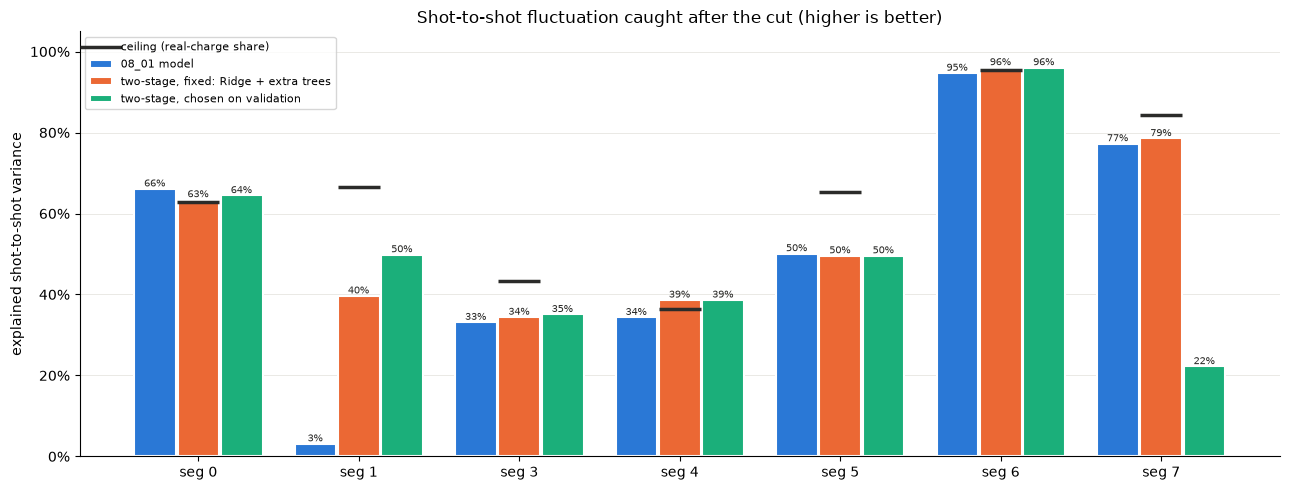

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(segments))
for dx, col, color, label in [(-0.27, "shot-to-shot explained: 08_01", BASE, "08_01 model"),
                              (0, "shot-to-shot explained: fixed", PICK, f"two-stage, fixed: {FIXED}"),
                              (0.27, "shot-to-shot explained: chosen", "#1baf7a", "two-stage, chosen on validation")]:
    vals = summary.loc[list(segments), col].astype(float)
    ax.bar(x + dx, vals, width=0.26, color=color, label=label, edgecolor="white", linewidth=1.5)
    for xi, val in zip(x + dx, vals):
        ax.text(xi, max(val, 0), f"{val:.0%}", ha="center", va="bottom", fontsize=7, color=INK)
ax.scatter(x, summary.loc[list(segments), "ceiling"].astype(float), marker="_", s=900, linewidths=2.5, color=CEIL,
           label="ceiling (real-charge share)", zorder=3)
ax.set_xticks(x, [f"seg {k}" for k in segments])
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(ylabel="explained shot-to-shot variance", title="Shot-to-shot fluctuation caught after the cut (higher is better)")
ax.legend(fontsize=8, loc="upper left")
ax.grid(axis="y", color=GRID, lw=0.6)
ax.set_axisbelow(True)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "shot_to_shot_vs_ceiling.png", dpi=130, bbox_inches="tight")

In [6]:
# every stage-2 model on the test shots
table = pd.DataFrame({k: test_scores[k]["shot-to-shot explained"] for k in segments}).loc[METHODS]
table["mean"] = table.mean(axis=1)
table.style.format("{:.0%}").set_caption("explained shot-to-shot variance on the test shots, all models")

,0,1,3,4,5,6,7,mean
stage 1 only (08_01),66%,3%,33%,34%,50%,95%,77%,51%
Ridge,46%,28%,32%,28%,45%,96%,78%,50%
deep gradient boosting,66%,48%,31%,34%,52%,92%,22%,49%
extra trees,64%,47%,35%,42%,52%,90%,20%,50%
RBF kernel,64%,50%,35%,41%,35%,90%,14%,47%
Ridge + extra trees,63%,40%,34%,39%,50%,96%,79%,57%


## Shot by shot, zoomed in

200 shots right after the cut: measured BCM (black), 08_01 model (blue), two-stage with the fixed model (orange).

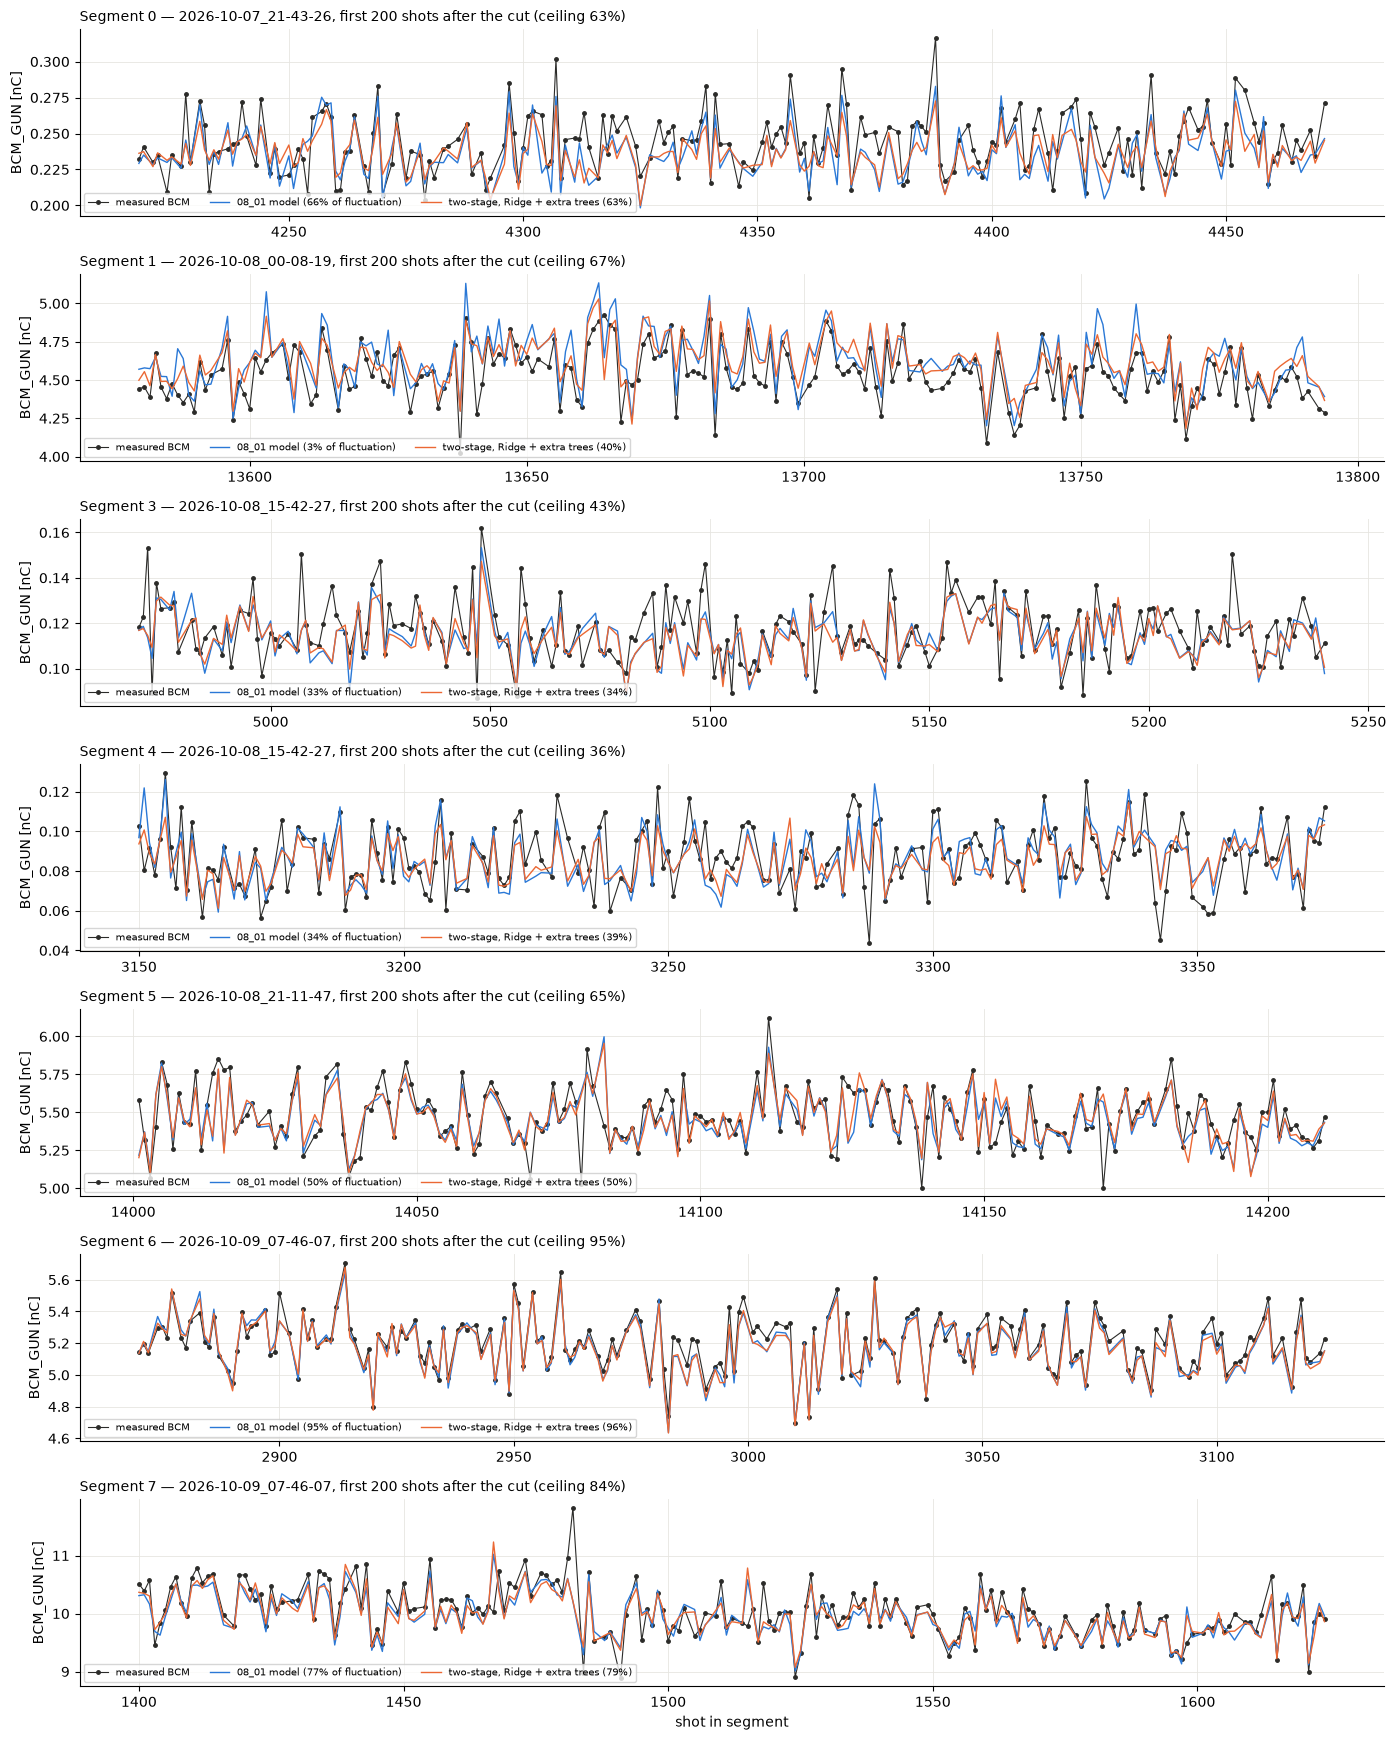

In [7]:
ZOOM = 200
fig, axes = plt.subplots(len(segments), 1, figsize=(14, 2.5 * len(segments)), squeeze=False)
for ax, (k, s) in zip(axes[:, 0], segments.items()):
    sp, pt = splits[k], preds[k]
    shots = np.flatnonzero(sp["test"])[:ZOOM]
    first = np.searchsorted(np.flatnonzero(sp["test"]), shots[0])
    sel = slice(first, first + len(shots))
    chosen = FIXED
    ax.plot(shots, s["y"][shots], "-o", ms=2.5, lw=0.8, color=INK, label="measured BCM")
    ax.plot(shots, pt["stage 1 only (08_01)"][sel], "-", lw=1.0, color=BASE,
            label=f"08_01 model ({test_scores[k].loc['stage 1 only (08_01)', 'shot-to-shot explained']:.0%} of fluctuation)")
    ax.plot(shots, pt[chosen][sel], "-", lw=1.0, color=PICK,
            label=f"two-stage, {chosen} ({test_scores[k].loc[chosen, 'shot-to-shot explained']:.0%})")
    ax.set_title(f"Segment {k} — {s['run'].removeprefix('acquisition_')}, first {ZOOM} shots after the cut "
                 f"(ceiling {ceiling.loc[k, 'real charge in BCM fluctuation (ceiling)']:.0%})", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=3)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / "shot_to_shot_zoom.png", dpi=130, bbox_inches="tight")